# RocketPy Simulation
Comparação entre OpenRocket e RocketPy usando Rocket Serialization



In [1]:
%pip install rocketpy<=2.0


Note: you may need to restart the kernel to use updated packages.


The system cannot find the file specified.


In [2]:
from rocketpy import Environment, SolidMotor, Rocket, Flight, TrapezoidalFins, EllipticalFins, RailButtons, NoseCone, Tail, Parachute
import datetime


## Environment


In [3]:
env = Environment()
env.set_location(latitude=31.049806, longitude=-103.547306)
env.set_elevation(980.0)


Optionally, you can set the date and atmospheric model


In [4]:
tomorrow = datetime.date.today() + datetime.timedelta(days=1)
env.set_date((tomorrow.year, tomorrow.month, tomorrow.day, 12))
env.set_atmospheric_model(type='Forecast', file='GFS')


Gravity Details

Acceleration of gravity at surface level:    9.7775 m/s²
Acceleration of gravity at  78.825 km (ASL): 9.5414 m/s²


Launch Site Details

Launch Date: 2026-11-10 12:00:00 UTC
Launch Site Latitude: 31.04981°
Launch Site Longitude: -103.54731°
Reference Datum: SIRGAS2000
Launch Site UTM coordinates: 166021.44 W|E    0.00 N
Launch Site UTM zone: 31N
Launch Site Surface Elevation: 921.2 m


Atmospheric Model Details

Atmospheric Model Type: Forecast
Forecast Maximum Height: 78.825 km
Forecast Time Period: from 2026-11-02 00:00:00 to 2026-11-25 06:00:00 utc
Forecast Hour Interval: 3 hrs
Forecast Latitude Range: From 90.0° to -90.0°
Forecast Longitude Range: From 0.0° to 359.75°

Surface Atmospheric Conditions

Surface Wind Speed: 0.65 m/s
Surface Wind Direction: 311.44°
Surface Wind Heading: 131.44°
Surface Pressure: 914.42 hPa
Surface Temperature: 287.98 K
Surface Air Density: 1.106 kg/m³
Surface Speed of Sound: 340.19 m/s


Earth Model Details

Earth Radius at Launch site

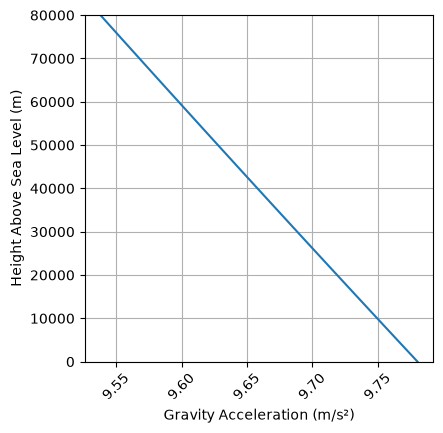



Atmospheric Model Plots


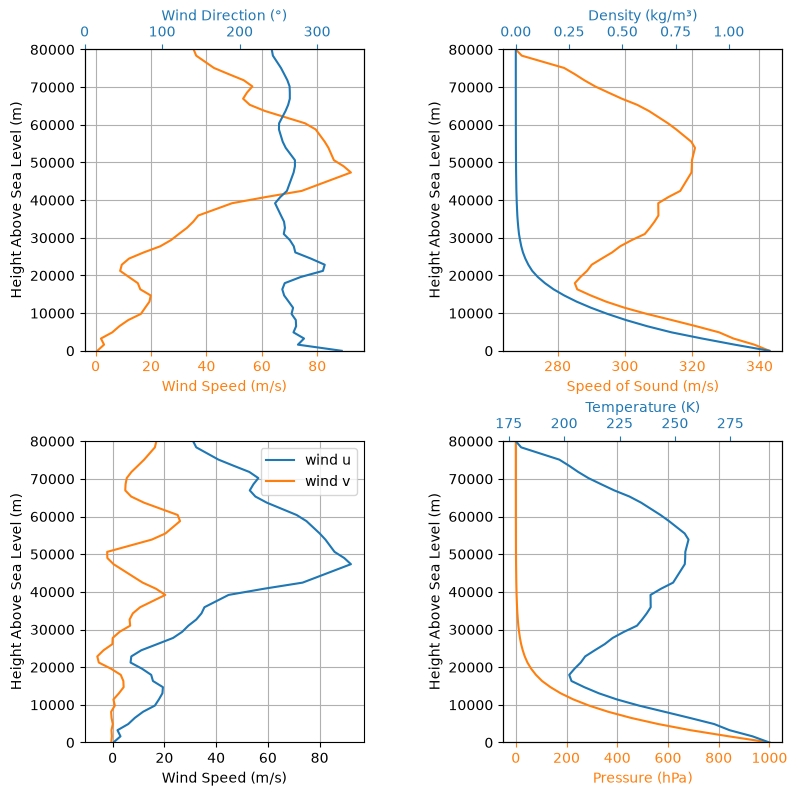

In [5]:
env.all_info()


## Motor
Currently, only Solid Motors are supported by Rocket-Serializer. If you want to use a Liquid/Hybrid motor, please use rocketpy directly.


In [6]:
motor = SolidMotor(
    thrust_source='thrust_source.csv',
    dry_mass=0,
    center_of_dry_mass_position=0,
    dry_inertia=[0, 0, 0],
    grains_center_of_mass_position=0,
    grain_number=1,
    grain_density=1006.8289309591454,
    grain_outer_radius=0.027,
    grain_initial_inner_radius=0.0135,
    grain_initial_height=0.728,
    grain_separation=0,
    nozzle_radius=0.02025,
    nozzle_position=-0.364,
    throat_radius=0.0135,
    reshape_thrust_curve=False,  # Not implemented in Rocket-Serializer
    interpolation_method='linear',
    coordinate_system_orientation='nozzle_to_combustion_chamber',
)


Nozzle Details
Nozzle Radius: 0.02025 m
Nozzle Throat Radius: 0.0135 m

Grain Details
Number of Grains: 1
Grain Spacing: 0 m
Grain Density: 1006.8289309591454 kg/m3
Grain Outer Radius: 0.027 m
Grain Inner Radius: 0.0135 m
Grain Height: 0.728 m
Grain Volume: 0.001 m3
Grain Mass: 1.259 kg

Motor Details
Total Burning Time: 2.169 s
Total Propellant Mass: 1.259 kg
Structural Mass Ratio: 0.000
Average Propellant Exhaust Velocity: 1786.645 m/s
Average Thrust: 1040.419 N
Maximum Thrust: 1574.366 N at 0.007 s after ignition.
Total Impulse: 2249.386 Ns



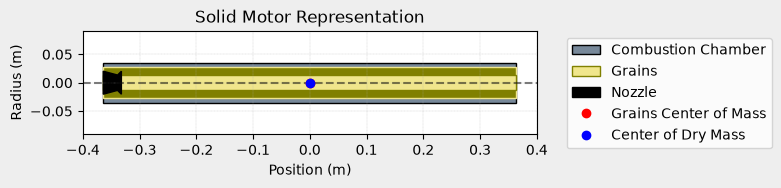

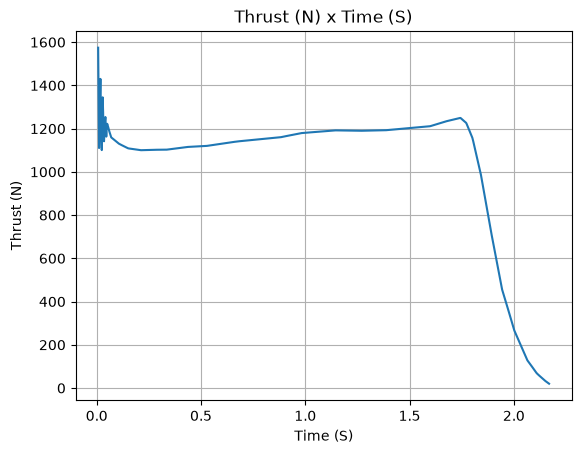

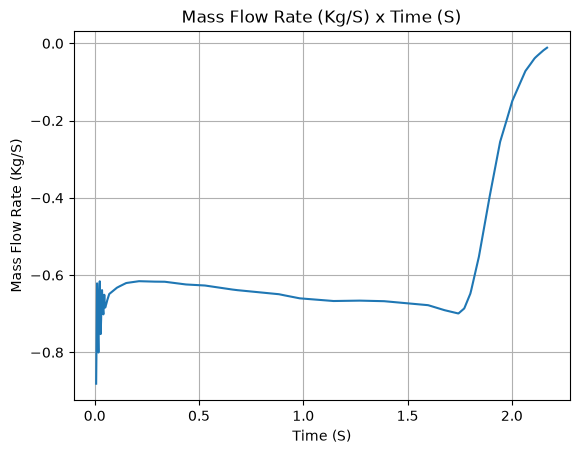

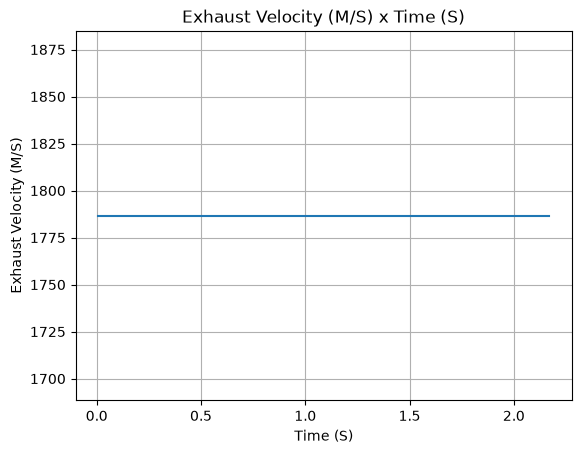

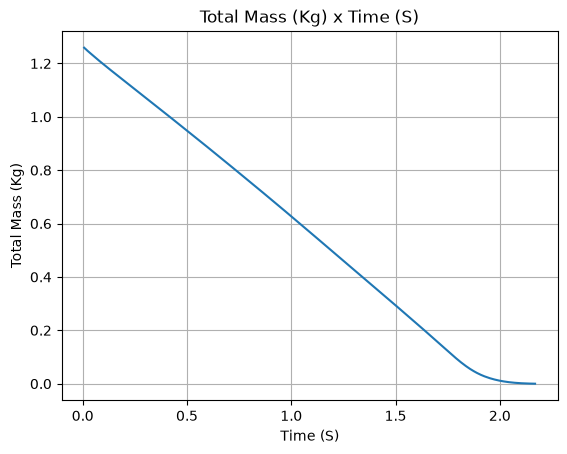

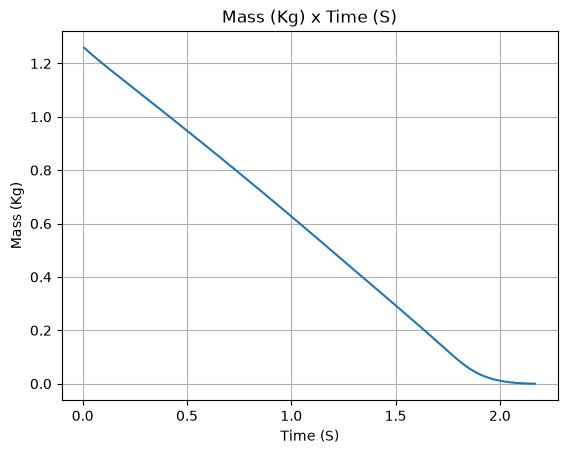

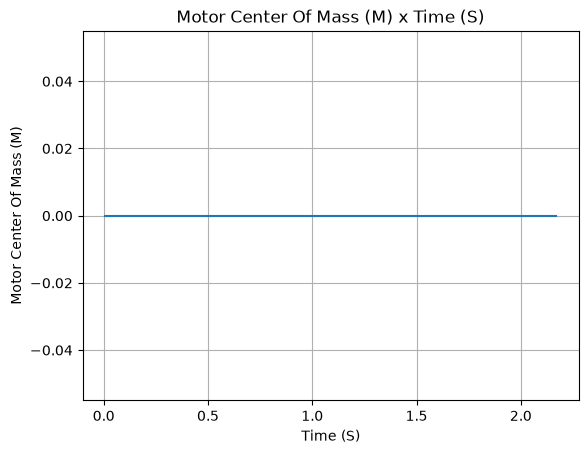

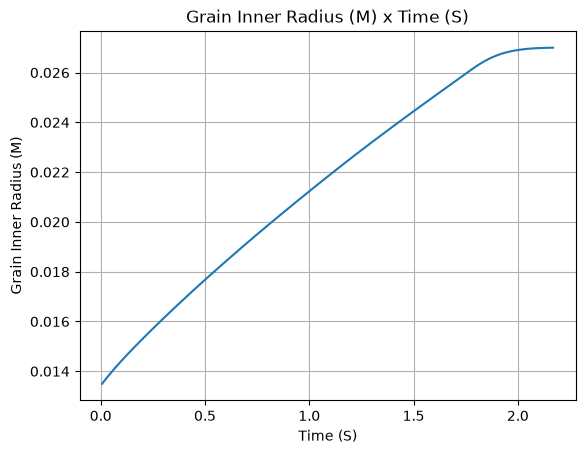

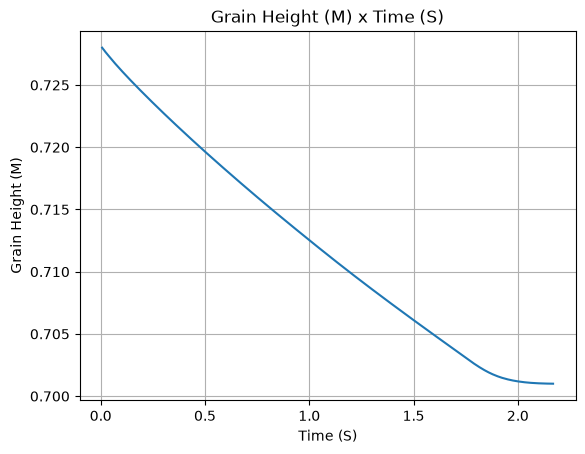

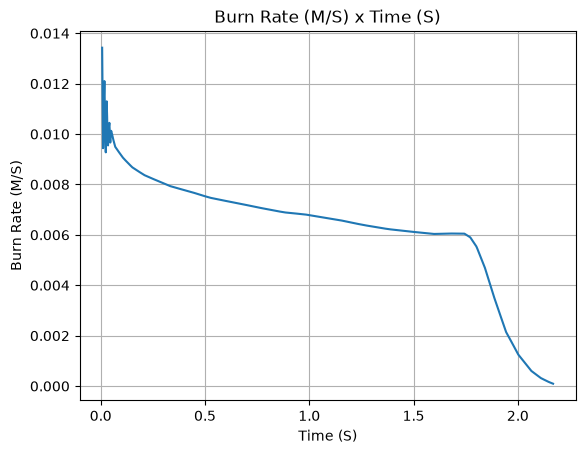

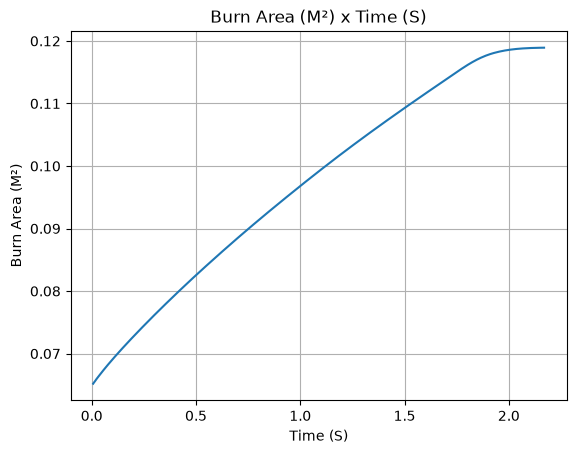

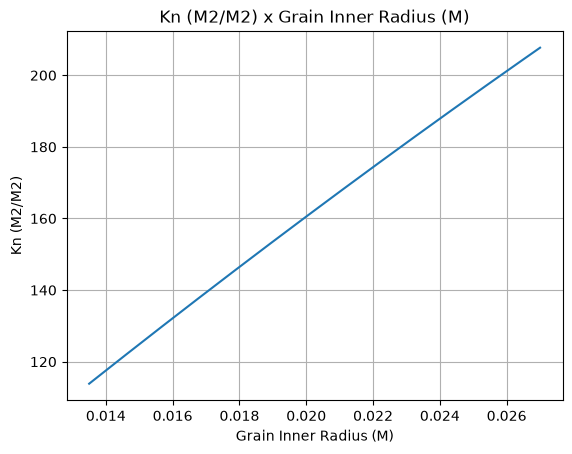

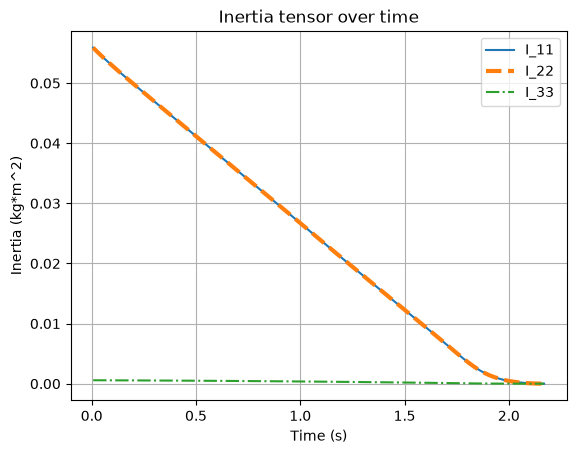

In [7]:
motor.all_info()


## Rocket

### Nosecones


In [8]:
nosecone = NoseCone(
    length=0.7000000000000001,
    kind='Von Karman',
    base_radius=0.03749936499873,
    rocket_radius=0.03749936499873,
    name='0.7000000000000001',
)


### Fins
As rocketpy allows for multiple fins sets, we will create a dictionary with all the fins sets and then add them to the rocket


In [9]:
trapezoidal_fins = {}


In [10]:
trapezoidal_fins[0] = TrapezoidalFins(
    n=3,
    root_chord=0.11000000000000006,
    tip_chord=0.04500127000254002,
    span=0.08,
    cant_angle=0.0,
    sweep_length= 0.09,
    sweep_angle= None,
    rocket_radius=0.03749936499873,
    name='Fin',
)



### Transitions (Tails)
As rocketpy allows for multiple tails, we will create a dictionary with all the tails and then add them to the rocket


In [11]:
tails = {}


### Parachutes
As rocketpy allows for multiple parachutes, we will create a dictionary with all the parachutes and then add them to the rocket


In [12]:
parachutes = {}


In [13]:
parachutes[0] = Parachute(
    name='SkyAngle Classic 20 [Cd 0.8 (3 oz) 20.8 in^3]',
    cd_s=0.162,
    trigger=300.000,
    sampling_rate=100, 
)


In [14]:
rocket = Rocket(
    radius=0.03749936499873,
    mass=2.414,
    inertia=[0.001, 0.001, 0.246],
    power_off_drag='poweroff.csv',
    power_on_drag='poweron.csv',
    center_of_mass_without_motor=0.896,
    coordinate_system_orientation='nose_to_tail',
)


c:\Python314\Lib\site-packages\rocketpy\mathutils\_calc\polation_1d.py:119: RuntimeWarning: divide by zero encountered in divide
  self._slopes = np.diff(self._y) / np.diff(self._x)


### Adding surfaces to the rocket


In [15]:
rocket.add_surfaces(surfaces=[nosecone, trapezoidal_fins[0]], positions=[0.0, 1.3399999999999999])

In [16]:
rocket.add_motor(motor, position= 1.0856306592533758)


Adding parachutes to the rocket


In [17]:
rocket.parachutes = list(parachutes.values())


### Rail Buttons


In [18]:
# No rail buttons were added to the rocket.


Inertia Details

Rocket Mass: 2.414 kg (without motor)
Rocket Dry Mass: 2.414 kg (with unloaded motor)
Rocket Loaded Mass: 3.673 kg
Rocket Structural Mass Ratio: 0.657
Rocket Inertia (with unloaded motor) 11: 0.001 kg*m2
Rocket Inertia (with unloaded motor) 22: 0.001 kg*m2
Rocket Inertia (with unloaded motor) 33: 0.246 kg*m2
Rocket Inertia (with unloaded motor) 12: 0.000 kg*m2
Rocket Inertia (with unloaded motor) 13: 0.000 kg*m2
Rocket Inertia (with unloaded motor) 23: 0.000 kg*m2

Geometrical Parameters

Rocket Maximum Radius: 0.03749936499873 m
Rocket Frontal Area: 0.004418 m2

Rocket Distances
Rocket Center of Dry Mass - Center of Mass without Motor: 0.000 m
Rocket Center of Dry Mass - Nozzle Exit: 0.554 m
Rocket Center of Dry Mass - Center of Propellant Mass: 0.190 m
Rocket Center of Mass - Rocket Loaded Center of Mass: 0.065 m


Aerodynamics Lift Coefficient Derivatives

0.7000000000000001 Lift Coefficient Derivative: 2.000/rad
Fin Lift Coefficient Derivative: 6.881/rad

Center o

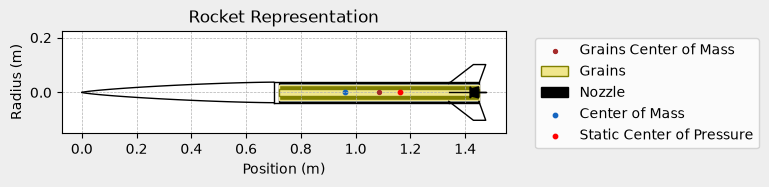


Mass Plots
----------------------------------------


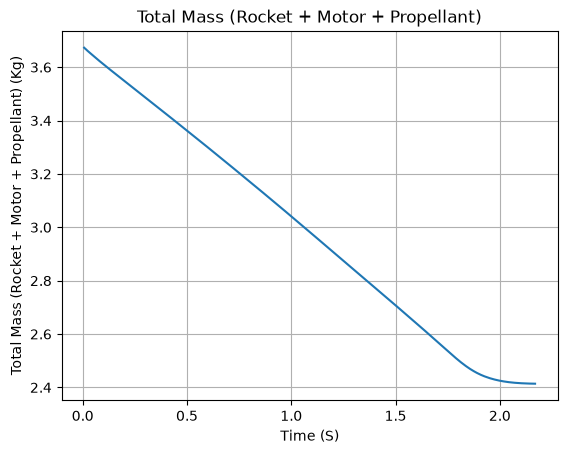

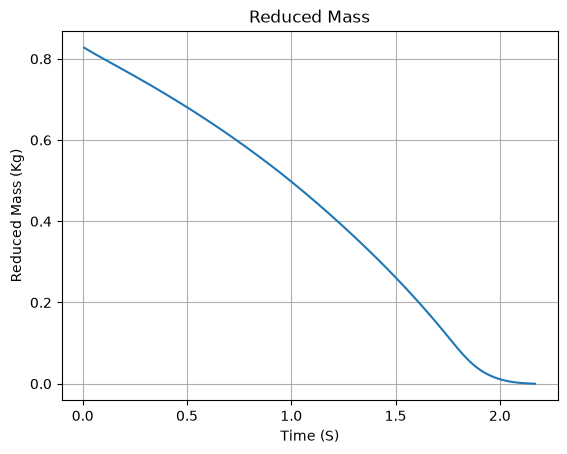


Aerodynamics Plots
----------------------------------------
Drag Plots
--------------------


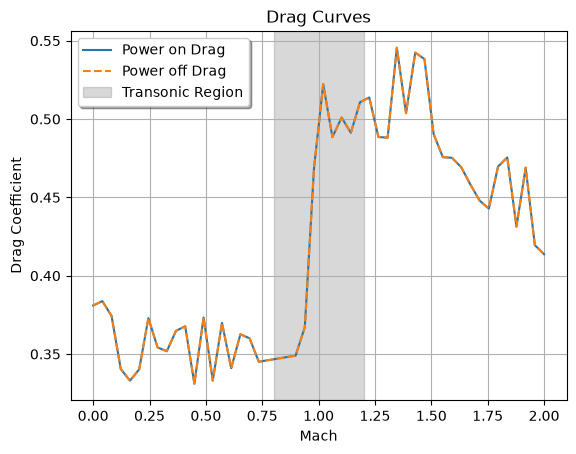


Stability Plots
--------------------


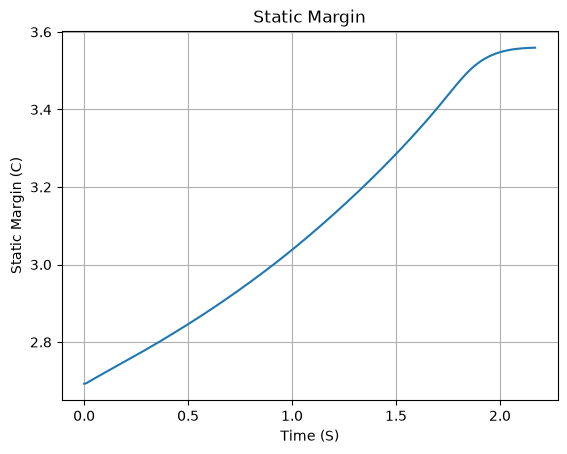

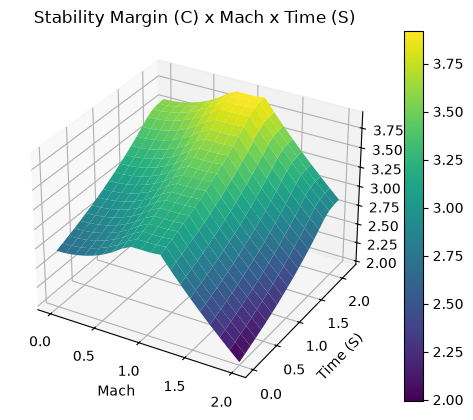


Thrust-to-Weight Plot
----------------------------------------


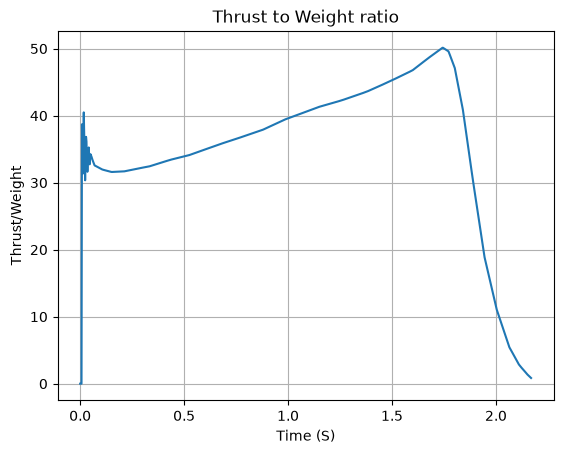

In [19]:
### Rocket Info
rocket.all_info()


## Flight



In [20]:
flight = Flight(
    rocket=rocket,
    environment=env,
    rail_length=1.0,
    inclination=90.0,
    heading=90.0,
    terminate_on_apogee=False,
    max_time=600,
)

## Compare Results



In [21]:
### OpenRocket vs RocketPy Parameters
time_to_apogee_ork = 23.258
time_to_apogee_rpy = flight.apogee_time
print(f"Time to apogee (OpenRocket): {time_to_apogee_ork:.3f} s")
print(f"Time to apogee (RocketPy):   {time_to_apogee_rpy:.3f} s")
apogee_difference = time_to_apogee_rpy - time_to_apogee_ork
error = abs((apogee_difference)/time_to_apogee_rpy)*100
print(f"Time to apogee difference:   {error:.3f} %")
print()

flight_time_ork = 226.219
flight_time_rpy = flight.t_final
print(f"Flight time (OpenRocket): {flight_time_ork:.3f} s")
print(f"Flight time (RocketPy):   {flight_time_rpy:.3f} s")
flight_time_difference = flight_time_rpy - flight_time_ork
error_flight_time = abs((flight_time_difference)/flight_time_rpy)*100
print(f"Flight time difference:   {error_flight_time:.3f} %")
print()

ground_hit_velocity_ork = -16.336
ground_hit_velocity_rpy = flight.impact_velocity
print(f"Ground hit velocity (OpenRocket): {ground_hit_velocity_ork:.3f} m/s")
print(f"Ground hit velocity (RocketPy):   {ground_hit_velocity_rpy:.3f} m/s")
ground_hit_velocity_difference = ground_hit_velocity_rpy - ground_hit_velocity_ork
error_ground_hit_velocity = abs((ground_hit_velocity_difference)/ground_hit_velocity_rpy)*100
print(f"Ground hit velocity difference:   {error_ground_hit_velocity:.3f} %")
print()

launch_rod_velocity_ork = 25.68
launch_rod_velocity_rpy = flight.out_of_rail_velocity
print(f"Launch rod velocity (OpenRocket): {launch_rod_velocity_ork:.3f} m/s")
print(f"Launch rod velocity (RocketPy):   {launch_rod_velocity_rpy:.3f} m/s")
launch_rod_velocity_difference = launch_rod_velocity_rpy - launch_rod_velocity_ork
error_launch_rod_velocity = abs((launch_rod_velocity_difference)/launch_rod_velocity_rpy)*100
print(f"Launch rod velocity difference:   {error_launch_rod_velocity:.3f} %")
print()

max_acceleration_ork = 419.2
max_acceleration_rpy = flight.max_acceleration
print(f"Max acceleration (OpenRocket): {max_acceleration_ork:.3f} m/s²")
print(f"Max acceleration (RocketPy):   {max_acceleration_rpy:.3f} m/s²")
max_acceleration_difference = max_acceleration_rpy - max_acceleration_ork
error_max_acceleration = abs((max_acceleration_difference)/max_acceleration_rpy)*100
print(f"Max acceleration difference:   {error_max_acceleration:.3f} %")
print()

max_altitude_ork = 4024.262
max_altitude_rpy = flight.apogee - flight.env.elevation
print(f"Max altitude (OpenRocket): {max_altitude_ork:.3f} m")
print(f"Max altitude (RocketPy):   {max_altitude_rpy:.3f} m")
max_altitude_difference = max_altitude_rpy - max_altitude_ork
error_max_altitude = abs((max_altitude_difference)/max_altitude_rpy)*100
print(f"Max altitude difference:   {error_max_altitude:.3f} %")
print()

max_mach_ork = 1.826
max_mach_rpy = flight.max_mach_number 
print(f"Max Mach (OpenRocket): {max_mach_ork:.3f}")
print(f"Max Mach (RocketPy):   {max_mach_rpy:.3f}")
max_mach_difference = max_mach_rpy - max_mach_ork
error_max_mach = abs((max_mach_difference)/max_mach_rpy)*100
print(f"Max Mach difference:   {error_max_mach:.3f} %")
print()

max_velocity_ork = 610.105
max_velocity_rpy = flight.max_speed
print(f"Max velocity (OpenRocket): {max_velocity_ork:.3f} m/s")
print(f"Max velocity (RocketPy):   {max_velocity_rpy:.3f} m/s")
max_velocity_difference = max_velocity_rpy - max_velocity_ork
error_max_velocity = abs((max_velocity_difference)/max_velocity_rpy)*100
print(f"Max velocity difference:   {error_max_velocity:.3f} %")
print()

max_thrust_ork = 1574.366
max_thrust_rpy = flight.rocket.motor.thrust.max
print(f"Max thrust (OpenRocket): {max_thrust_ork:.3f} N")
print(f"Max thrust (RocketPy):   {max_thrust_rpy:.3f} N")
max_thrust_difference = max_thrust_rpy - max_thrust_ork
error_max_thrust = abs((max_thrust_difference)/max_thrust_rpy)*100
print(f"Max thrust difference:   {error_max_thrust:.3f} %")
print()

burnout_stability_margin_ork = 2.901
burnout_stability_margin_rpy = flight.stability_margin(flight.rocket.motor.burn_out_time)
print(f"Burnout stability margin (OpenRocket): {burnout_stability_margin_ork:.3f}")
print(f"Burnout stability margin (RocketPy):   {burnout_stability_margin_rpy:.3f}")
burnout_stability_margin_difference = burnout_stability_margin_rpy - burnout_stability_margin_ork
error_burnout_stability_margin = abs((burnout_stability_margin_difference)/burnout_stability_margin_rpy)*100
print(f"Burnout stability margin difference:   {error_burnout_stability_margin:.3f} %")
print()

max_stability_margin_ork = 5.545
max_stability_margin_rpy = flight.max_stability_margin
print(f"Max stability margin (OpenRocket): {max_stability_margin_ork:.3f}")
print(f"Max stability margin (RocketPy):   {max_stability_margin_rpy:.3f}")
max_stability_margin_difference = max_stability_margin_rpy - max_stability_margin_ork
error_max_stability_margin = abs((max_stability_margin_difference)/max_stability_margin_rpy)*100
print(f"Max stability margin difference:   {error_max_stability_margin:.3f} %")
print()

min_stability_margin_ork = 0.0
min_stability_margin_rpy = flight.min_stability_margin
print(f"Min stability margin (OpenRocket): {min_stability_margin_ork:.3f}")
print(f"Min stability margin (RocketPy):   {min_stability_margin_rpy:.3f}")
min_stability_margin_difference = min_stability_margin_rpy - min_stability_margin_ork
error_min_stability_margin = abs((min_stability_margin_difference)/min_stability_margin_rpy)*100
print(f"Min stability margin difference:   {error_min_stability_margin:.3f} %")
print()



Time to apogee (OpenRocket): 23.258 s
Time to apogee (RocketPy):   25.464 s
Time to apogee difference:   8.665 %

Flight time (OpenRocket): 226.219 s
Flight time (RocketPy):   75.602 s
Flight time difference:   199.224 %

Ground hit velocity (OpenRocket): -16.336 m/s
Ground hit velocity (RocketPy):   -16.242 m/s
Ground hit velocity difference:   0.580 %

Launch rod velocity (OpenRocket): 25.680 m/s
Launch rod velocity (RocketPy):   25.146 m/s
Launch rod velocity difference:   2.123 %

Max acceleration (OpenRocket): 419.200 m/s²
Max acceleration (RocketPy):   1056.803 m/s²
Max acceleration difference:   60.333 %

Max altitude (OpenRocket): 4024.262 m
Max altitude (RocketPy):   4476.790 m
Max altitude difference:   10.108 %

Max Mach (OpenRocket): 1.826
Max Mach (RocketPy):   1.801
Max Mach difference:   1.362 %

Max velocity (OpenRocket): 610.105 m/s
Max velocity (RocketPy):   610.407 m/s
Max velocity difference:   0.050 %

Max thrust (OpenRocket): 1574.366 N
Max thrust (RocketPy):   15